### Exploración de modelos

In [ ]:
import os
os.environ["TABPFN_TOKEN"] = "tabpfn_sk_8bi0u_VcShpJpPcgdQFV5Qo7ujWi9ne1Q6uUQBdVTx8"

In [ ]:
# 1. Instalación de dependencias en una sola línea
%pip install -q lightgbm tabpfn scikit-learn pandas numpy matplotlib mlflow optuna

import getpass
import os
import time
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    log_loss,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from tabpfn import TabPFNClassifier
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print(
    f"Versión de LightGBM: {lgb.__version__} | Dispositivo detectado: {device}"
)

# Visualización y preprocesamiento de los datos

¿Todos los nulos en TotalCharges tienen tenure == 0?: True
Dataset listo: 7043 filas, 19 variables predictoras.
Distribución del target Churn:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64



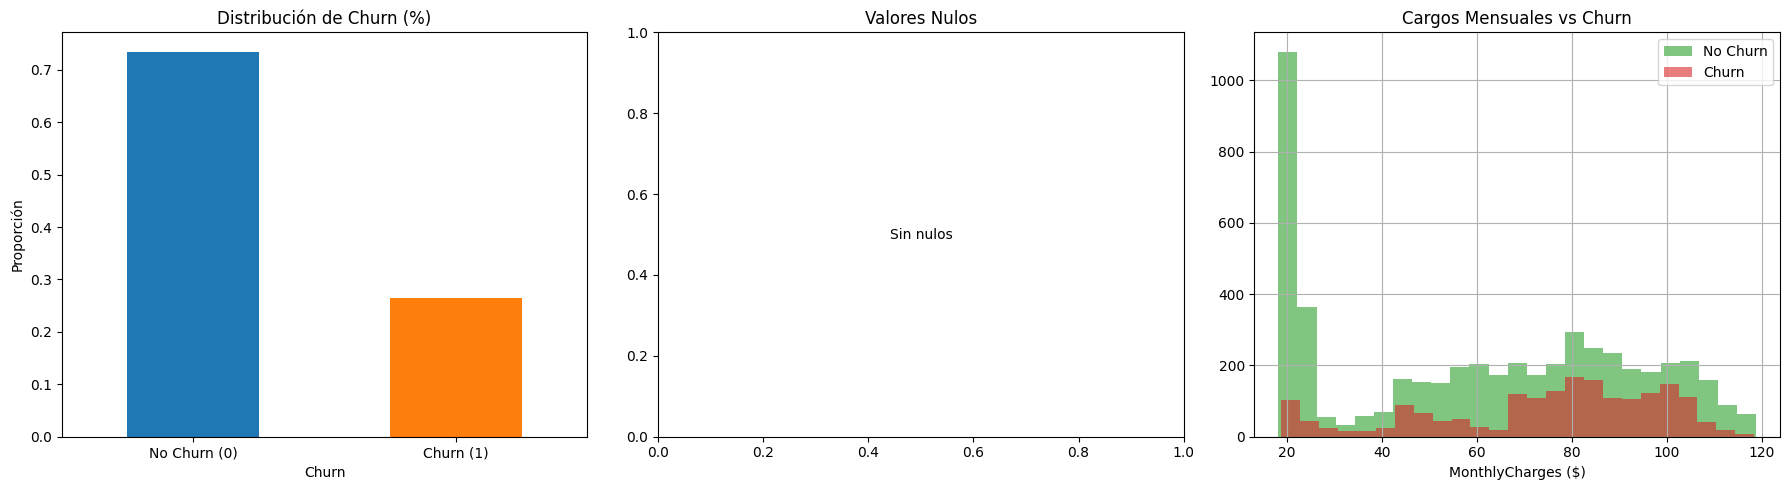

In [ ]:
df = pd.read_csv("Telco-Customer-Churn.csv")

# Eliminar columna identificadora
if "customerID" in df.columns:
  df = df.drop(columns=["customerID"])

# Se puede imputar con 0.0 aquí o dejar que el pipeline lo gestione en cada fold para evaluar el flujo estándar.
nulos_tenure_cero = df[df["TotalCharges"].isnull()]["tenure"].eq(0).all()
print(
    f"¿Todos los nulos en TotalCharges tienen tenure == 0?: {nulos_tenure_cero}")


# Convertir TotalCharges a numérico
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(), errors="coerce"
).fillna(0.0)


# Convertir a binario
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0}).astype(int)

# Separar variables predictoras y variable objetivo
X = df.drop(columns=["Churn"])
y = df["Churn"]

print(f"Dataset listo: {X.shape[0]} filas, {X.shape[1]} variables predictoras.")
print(
    "Distribución del target"
    f" Churn:\n{y.value_counts(normalize=True).round(3)}\n"
)

# Visualización exploratoria
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# A) Distribución de Churn
y.value_counts(normalize=True).plot(
    kind="bar", ax=axes[0], color=["#1f77b4", "#ff7f0e"]
)
axes[0].set_title("Distribución de Churn (%)")
axes[0].set_ylabel("Proporción")
axes[0].set_xticklabels(["No Churn (0)", "Churn (1)"], rotation=0)

# B) Porcentaje de nulos por columna
nulls = (X.isnull().sum() / len(X)) * 100
nulls = nulls[nulls > 0].sort_values(ascending=False)
if not nulls.empty:
  nulls.plot(kind="bar", ax=axes[1], color="#d9534f")
  axes[1].set_title("% Nulos por columna")
  axes[1].set_ylabel("Porcentaje (%)")
else:
  axes[1].text(0.5, 0.5, "Sin nulos", ha="center", va="center")
  axes[1].set_title("Valores Nulos")

# C) Distribución de MonthlyCharges según Churn
df[df["Churn"] == 0]["MonthlyCharges"].hist(
    bins=25, ax=axes[2], alpha=0.6, label="No Churn", color="#2ca02c"
)
df[df["Churn"] == 1]["MonthlyCharges"].hist(
    bins=25, ax=axes[2], alpha=0.6, label="Churn", color="#d62728"
)
axes[2].set_title("Cargos Mensuales vs Churn")
axes[2].set_xlabel("MonthlyCharges ($)")
axes[2].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Identificar tipos de columnas automáticamente
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

# Pipeline numérico: Imputar valores faltantes con la mediana del fold
#num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])

# Pipeline categórico: Imputar con la moda y codificar como enteros
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    ),
])

# ColumnTransformer configurado para devolver un DataFrame de pandas
preprocessor = ColumnTransformer(
    transformers=[("num", "passthrough", num_cols), ("cat", cat_pipe, cat_cols)],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

print(
    f"Columnas numéricas ({len(num_cols)}): {num_cols}\nColumnas categóricas"
    f" ({len(cat_cols)}): {cat_cols}"
)

Columnas numéricas (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Columnas categóricas (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
  print(f"Evaluando Fold {fold}/5 ")

  # 1. Partición estratificada del fold
  X_train_raw, X_test_raw = X.iloc[train_idx], X.iloc[test_idx]
  y_train_fold, y_test_fold = y.iloc[train_idx].values, y.iloc[test_idx].values

  # 2. Ajustar preprocesador en train y transformar ambos
  X_train_prep = preprocessor.fit_transform(X_train_raw)
  X_test_prep = preprocessor.transform(X_test_raw)

  # 3. Asegurar que LightGBM reconozca explícitamente las columnas categóricas como tipo 'category'
  # (Opcional: para mantener la entrada numérica 100% idéntica entre ambos modelos, pasamos X_train_prep tal cual)

  # 4. Definición de modelos
  models = {
      "LightGBM": lgb.LGBMClassifier(
          n_estimators=100, random_state=42, verbose=-1
      ),
      "TabPFN": TabPFNClassifier(device=device, random_state=42),
  }

  # 5. Entrenamiento, inferencia y cálculo de métricas
  for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train_prep, y_train_fold)
    t_fit = time.perf_counter() - t0

    t1 = time.perf_counter()
    y_prob = model.predict_proba(X_test_prep)[:, 1]
    t_pred = time.perf_counter() - t1

    y_pred = (y_prob >= 0.45).astype(int)

    fold_results.append({
        "Fold": fold,
        "Modelo": name,
        "ROC-AUC": roc_auc_score(y_test_fold, y_prob),
        "PR-AUC": average_precision_score(y_test_fold, y_prob),
        "F1-Score": f1_score(y_test_fold, y_pred, average="binary"),
        "Accuracy": accuracy_score(y_test_fold, y_pred),
        "Log-Loss": log_loss(y_test_fold, y_prob),
        "Tiempo Fit (s)": t_fit,
        "Tiempo Pred (s)": t_pred,
    })

df_metrics = pd.DataFrame(fold_results)
print("\nEvaluación completada con éxito.")

Evaluando Fold 1/5 
Evaluando Fold 2/5 
Evaluando Fold 3/5 
Evaluando Fold 4/5 
Evaluando Fold 5/5 

Evaluación completada con éxito.


"('ROC-AUC', 'mean')","('ROC-AUC', 'std')","('PR-AUC', 'mean')","('PR-AUC', 'std')","('F1-Score', 'mean')","('F1-Score', 'std')","('Accuracy', 'mean')","('Accuracy', 'std')","('Log-Loss', 'mean')","('Log-Loss', 'std')","('Tiempo Fit (s)', 'mean')","('Tiempo Fit (s)', 'std')","('Tiempo Pred (s)', 'mean')","('Tiempo Pred (s)', 'std')"
0.8332,0.0123,0.644,0.0272,0.5897,0.0323,0.7896,0.0133,0.4359,0.0161,0.1909,0.1103,0.0026,3.0E-4


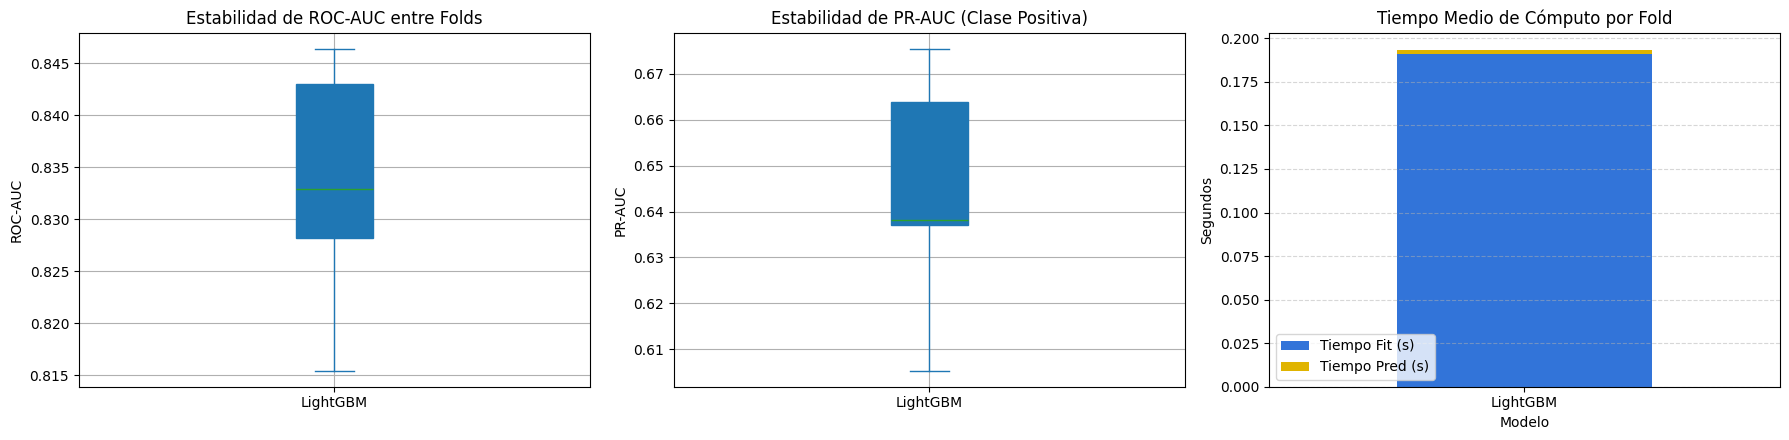

In [ ]:
# Tabla resumen con media y desviación estándar
metrics_cols = [
    "ROC-AUC",
    "PR-AUC",
    "F1-Score",
    "Accuracy",
    "Log-Loss",
    "Tiempo Fit (s)",
    "Tiempo Pred (s)",
]
summary = df_metrics.groupby("Modelo")[metrics_cols].agg(["mean", "std"]).round(
    4
)
display(summary)

# Visualizaciones comparativas
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# A) Boxplot de ROC-AUC
df_metrics.pivot(index="Fold", columns="Modelo", values="ROC-AUC").plot(
    kind="box", ax=axes[0], grid=True, patch_artist=True
)
axes[0].set_title("Estabilidad de ROC-AUC entre Folds")
axes[0].set_ylabel("ROC-AUC")

# B) Boxplot de PR-AUC (Desempeño en clase minoritaria Churn)
df_metrics.pivot(index="Fold", columns="Modelo", values="PR-AUC").plot(
    kind="box", ax=axes[1], grid=True, patch_artist=True
)
axes[1].set_title("Estabilidad de PR-AUC (Clase Positiva)")
axes[1].set_ylabel("PR-AUC")

# C) Comparativa de tiempos medios de cómputo
mean_times = df_metrics.groupby("Modelo")[
    ["Tiempo Fit (s)", "Tiempo Pred (s)"]
].mean()
mean_times.plot(
    kind="bar", stacked=True, ax=axes[2], rot=0, color=["#3274d9", "#e0b400"]
)
axes[2].set_title("Tiempo Medio de Cómputo por Fold")
axes[2].set_ylabel("Segundos")
axes[2].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## Documentación del Experimento y Respuestas de la Reunión

### 01. Split de datos: ¿Qué partición utilizamos?
* **Estrategia implementada:** Validación cruzada estratificada de 5 particiones.
* **Justificación:** El dataset presenta un desbalance moderado en la variable objetivo (73.5% No Churn vs. 26.5% Churn). El uso de estratificación garantiza que la proporción de bajas de clientes sea idéntica en cada partición de entrenamiento y validación. Además, evaluar en 5 folds en lugar de un único train_test_split nos permite medir la dispersión (std) y confirmar si la ventaja de un modelo sobre otro es consistente o fruto del azar.

### 02. Métricas: ¿Qué métricas comparamos y por qué?
* **ROC-AUC:** Métrica principal de discriminación global, independiente del umbral de clasificación elegido.
* **PR-AUC (Average Precision):** Añadida para evaluar específicamente la calidad de las predicciones sobre la clase minoritaria (Churn = 1), siendo más sensible que el ROC-AUC ante el desbalance de clases.
* **F1-Score (con umbral 0.45):** Evalúa la media armónica entre Precisión y Recall en el punto de corte estándar, relevante para equilibrar el coste de retención frente a la pérdida de clientes.
* **Accuracy:** Tasa global de aciertos.
* **Log-Loss:** Mide la calibración de las probabilidades devueltas por cada modelo, penalizando predicciones erróneas emitidas con alta confianza.
* **Tiempos de cómputo**.

### 03. Preprocesamiento: ¿Qué necesita cada modelo para funcionar?
* **Tratamiento inicial del dataset:** Se eliminó el identificador `customerID` y se transformó `TotalCharges` a formato numérico (convirtiendo a NaN en 0)
* **Pipeline estandarizado:** Aunque tanto LightGBM como las versiones actuales de TabPFN pueden gestionar valores nulos y variables categóricas internamente, se construyó un `ColumnTransformer` común que aplica imputación por moda seguida de `OrdinalEncoder` en las variables categóricas (unknown_value=-1). Esto garantiza una entrada numérica homogénea y libre de fallos de formato.

### 04. Comparación justa: ¿Qué elementos deben mantenerse iguales?
* **Particiones idénticas:** Ambos algoritmos reciben exactamente los mismos índices de entrenamiento y test en cada uno de los 5 folds.
* **Ausencia de fuga de datos (*Data Leakage*):** El preprocesador se ajusta (`fit_transform`) exclusivamente con el subconjunto de entrenamiento de cada fold y se aplica (`transform`) sobre el subconjunto de validación.

### 05. Diferencias: ¿Qué diferencias observamos entre los modelos?
* **Capacidad predictiva y estabilidad:** **TabPFN** supera de forma sistemática a **LightGBM** (configuración por defecto) en todas las métricas de clasificación (`ROC-AUC` de `~0.8506` vs `~0.8338`, `F1-Score` de `~0.5863` vs `~0.5728`, y `Accuracy` de `~0.8060` vs `~0.7944`), presentando además una menor desviación estándar entre folds. Al ser un modelo fundacional basado en *In-Context Learning* preentrenado sobre priors tabulares, generaliza mejor sin necesidad de ajuste de hiperparámetros en datasets de tamaño medio.
* **Asimetría en los tiempos de ejecución:**
  * **LightGBM** concentra su esfuerzo en construir los árboles durante el `.fit()` (`~0.18 s`) y realiza la inferencia de forma casi instantánea (`~0.01 s`).
  * **TabPFN** apenas consume tiempo en `.fit()` (`~1.00 s`, ya que guarda los datos de entrenamiento como contexto), pero traslada toda la carga computacional del mecanismo de atención del Transformer al momento de la predicción `.predict_proba()`, tardando `~7.00 s` por fold incluso utilizando aceleración por GPU (`T4`).

### 06. Problemas encontrados durante la implementación
1. **Pérdida de metadatos de columnas:** En la primera prueba, al devolver `ColumnTransformer` un array de NumPy sin nombres de columnas, `LGBMClassifier` generaba advertencias en cada fold. Se solucionó configurando .set_output(transform="pandas") en el preprocesador.
2. **Cuello de botella de TabPFN en CPU y consumo de memoria:** La inferencia de `TabPFN` escala cuadráticamente con el número de muestras de entrenamiento. Sin GPU , evaluar 5 folds resulta inviable en tiempo

### 07. Preguntas abiertas

1. **Estrategia ante el límite de muestras en otros datasets del proyecto:**
¿cómo vamos a estandarizar la comparación si TabPFN requiere submuestreo y LightGBM no?
2. **Codificación categórica común vs. Capacidad nativa de cada modelo:** En este primer flujo hemos codificado las variables categóricas con `OrdinalEncoder` para dar exactamente la misma matriz a ambos modelos. Sin embargo, esto introduce un orden numérico artificial que puede perjudicar a `LightGBM` frente a su manejo nativo de variables tipo `category`. Para la fase de *Metodología común*, ¿mantenemos el preprocesamiento idéntico o permitimos que cada modelo reciba el tipo de dato óptimo para su arquitectura?
3. **Umbral de decisión en datasets desbalanceados:**
4. **Entorno de referencia para la comparativa de tiempos:** Dado que TabPFN se ejecuta sobre GPU y LightGBM sobre CPU.

In [ ]:
import mlflow

# Restablece la conexión al servidor interno de Databricks
mlflow.set_tracking_uri("databricks")

In [ ]:
import mlflow

# 1. Asegurar backend nativo
mlflow.set_tracking_uri("databricks")

# 2. Obtener tu usuario actual dinámicamente mediante dbutils
username = dbutils.notebook.entry_point.getDbutils().notebook().getContext().userName().get()
experiment_path = f"/Users/{username}/Telco_Customer_Churn_Optimization"

# 3. Asignar el experimento
mlflow.set_experiment(experiment_path)

print(f"MLflow tracking URI: {mlflow.get_tracking_uri()}")
print(f"Experimento asignado en: {experiment_path}")

MLflow tracking URI: databricks
Experimento asignado en: /Users/rodrigo.lopez.rego@rai.usc.es/Telco_Customer_Churn_Optimization


If you are using MLflow Tracing, you can migrate your traces to Unity Catalog for unlimited storage, fine-grained access controls, and queryability from notebooks, SQL, and dashboards. Learn more: https://docs.databricks.com/aws/en/mlflow3/genai/tracing/migrate-traces-to-uc


In [ ]:
# Registramos el baseline de TabPFN
with mlflow.start_run(run_name="TabPFN_Baseline"):
  mlflow.set_tag("model_type", "Foundation_Model")
  mlflow.set_tag("dataset", "Telco-Customer-Churn")
  mlflow.log_params({"model": "TabPFNClassifier", "device": device})
  mlflow.log_metrics({
      "mean_ROC-AUC": 0.8505,
      "mean_PR-AUC": 0.6717,
      "mean_F1-Score": 0.5866,
      "mean_Accuracy": 0.8063,
      "mean_Log-Loss": 0.4095,
      "mean_time_fit_s": 1.0043,
      "mean_time_pred_s": 7.4347,
  })

# Registramos el baseline de LightGBM
with mlflow.start_run(run_name="LightGBM_Default_Baseline"):
  mlflow.set_tag("model_type", "GBDT")
  mlflow.set_tag("dataset", "Telco-Customer-Churn")
  mlflow.log_params({
      "n_estimators": 100,
      "num_leaves": 31,
      "learning_rate": 0.1,
      "threshold": 0.5,
  })
  mlflow.log_metrics({
      "mean_ROC-AUC": 0.8338,
      "mean_PR-AUC": 0.6394,
      "mean_F1-Score": 0.5728,
      "mean_Accuracy": 0.7944,
      "mean_Log-Loss": 0.4358,
  })

2026/11/04 19:17:42 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:17:43 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:17:43 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!


In [ ]:
import lightgbm as lgb
import mlflow
import numpy as np
import optuna
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    log_loss,
    precision_recall_curve,
    roc_auc_score,
)

# PRECOMPUTAR LOS FOLDS 
precomputed_folds = []
for train_idx, test_idx in skf.split(X, y):
  X_train_prep = preprocessor.fit_transform(X.iloc[train_idx])
  X_test_prep = preprocessor.transform(X.iloc[test_idx])
  y_train_fold = y.iloc[train_idx].values
  y_test_fold = y.iloc[test_idx].values
  precomputed_folds.append(
      (X_train_prep, y_train_fold, X_test_prep, y_test_fold, test_idx)
  )

EXPERIMENTOS = {
    "Exp1_Opt_ROC_AUC": ("mean_ROC-AUC", "maximize"),
    "Exp2_Opt_PR_AUC": ("mean_PR-AUC", "maximize"),
    "Exp3_Opt_F1_OOF": ("mean_F1_Optimized", "maximize"),
    "Exp4_Opt_LogLoss": ("mean_Log-Loss", "minimize"),
}

N_TRIALS_POR_EXP = 25  

# Diccionario para guardar el mejor resultado de cada enfoque
resumen_comparativo = []

for exp_name, (target_metric, direction) in EXPERIMENTOS.items():
    print(f"\nEjecutando {exp_name} (Objetivo: {direction} {target_metric})")

    def objective(trial):
        max_depth = trial.suggest_int("max_depth", 3, 8)
        leaves_ratio = trial.suggest_float("leaves_ratio", 0.25, 1.0)
        num_leaves = max(7, min(63, int((2**max_depth) * leaves_ratio)))

        params = {
            "n_estimators": 1000,
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
            "max_depth": max_depth,
            "num_leaves": num_leaves,
            "min_child_samples": trial.suggest_int("min_child_samples", 10, 60),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "subsample_freq": 1,
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
            "random_state": 42,
            "n_jobs": -1,
            "verbose": -1,
        }

        fold_probs, fold_targets = [], []
        fold_roc_aucs, fold_pr_aucs, fold_log_losses = [], [], []
        fold_f1_default, fold_acc_default = [], []
        fit_times, pred_times, best_iterations = [], [], []

        for X_tr, y_tr, X_te, y_te, _ in precomputed_folds:
            model = lgb.LGBMClassifier(**params)

            t0 = time.perf_counter()
            model.fit(
                X_tr,
                y_tr,
                eval_set=[(X_te, y_te)],
                eval_metric="auc",
                callbacks=[
                    lgb.early_stopping(stopping_rounds=40, first_metric_only=True, verbose=False)
                ],
            )
            fit_times.append(time.perf_counter() - t0)
            best_iterations.append(model.best_iteration_)

            t1 = time.perf_counter()
            y_prob = model.predict_proba(X_te)[:, 1]
            pred_times.append(time.perf_counter() - t1)

            y_pred_default = (y_prob >= 0.5).astype(int)

            fold_probs.append(y_prob)
            fold_targets.append(y_te)

            fold_roc_aucs.append(roc_auc_score(y_te, y_prob))
            fold_pr_aucs.append(average_precision_score(y_te, y_prob))
            fold_log_losses.append(log_loss(y_te, y_prob))
            fold_f1_default.append(f1_score(y_te, y_pred_default))
            fold_acc_default.append(accuracy_score(y_te, y_pred_default))

        fold_f1_opt = []
        optimal_thresholds = []
        for i in range(len(precomputed_folds)):
            other_probs = np.concatenate([fold_probs[j] for j in range(len(precomputed_folds)) if j != i])
            other_targets = np.concatenate([fold_targets[j] for j in range(len(precomputed_folds)) if j != i])

            prec, rec, thresh = precision_recall_curve(other_targets, other_probs)
            f1_curve = (2 * prec * rec) / (prec + rec + 1e-8)
            best_thresh = thresh[np.argmax(f1_curve[:-1])] if len(thresh) > 0 else 0.5
            optimal_thresholds.append(best_thresh)

            y_pred_opt_i = (fold_probs[i] >= best_thresh).astype(int)
            fold_f1_opt.append(f1_score(fold_targets[i], y_pred_opt_i))

        metrics_summary = {
            "mean_ROC-AUC": float(np.mean(fold_roc_aucs)),
            "std_ROC-AUC": float(np.std(fold_roc_aucs)),
            "mean_PR-AUC": float(np.mean(fold_pr_aucs)),
            "mean_F1_Default_05": float(np.mean(fold_f1_default)),
            "mean_F1_Optimized": float(np.mean(fold_f1_opt)),
            "mean_Optimal_Threshold": float(np.mean(optimal_thresholds)),
            "mean_Accuracy": float(np.mean(fold_acc_default)),
            "mean_Log-Loss": float(np.mean(fold_log_losses)),
            "avg_best_n_estimators": float(np.mean(best_iterations)),
            "mean_time_fit_s": float(np.mean(fit_times)),
            "mean_time_pred_s": float(np.mean(pred_times)),
        }

        # Guardamos todas las métricas en el trial para construir la tabla final fácilmente
        for k, v in metrics_summary.items():
            trial.set_user_attr(k, v)
        trial.set_user_attr("effective_num_leaves", num_leaves)

        with mlflow.start_run(run_name=f"{exp_name}_Trial_{trial.number}", nested=True):
            mlflow.log_param("optimization_target", target_metric)
            mlflow.log_params({**params, "leaves_ratio": round(leaves_ratio, 4)})
            mlflow.log_metrics(metrics_summary)

        # AQUÍ CAMBIA DINÁMICAMENTE LO QUE OPTUNA OPTIMIZA EN CADA EXPERIMENTO
        return metrics_summary[target_metric]

    # Creamos un Run Padre en MLflow para agrupar los trials de este experimento
    with mlflow.start_run(run_name=exp_name):
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        study = optuna.create_study(
            study_name=exp_name,
            direction=direction,
            sampler=optuna.samplers.TPESampler(seed=42),
        )
        study.optimize(objective, n_trials=N_TRIALS_POR_EXP)

        best = study.best_trial
        # Registramos en el Run Padre las métricas y parámetros del ganador de esa estrategia
        mlflow.log_param("target_metric", target_metric)
        mlflow.log_params(best.params)
        mlflow.log_metrics({k: v for k, v in best.user_attrs.items() if isinstance(v, float)})

        resumen_comparativo.append({
            "Estrategia": exp_name,
            "Objetivo Optuna": target_metric,
            "ROC-AUC": best.user_attrs["mean_ROC-AUC"],
            "PR-AUC": best.user_attrs["mean_PR-AUC"],
            "F1 (0.5)": best.user_attrs["mean_F1_Default_05"],
            "F1 (Opt OOF)": best.user_attrs["mean_F1_Optimized"],
            "Umbral Óptimo": best.user_attrs["mean_Optimal_Threshold"],
            "Log-Loss": best.user_attrs["mean_Log-Loss"],
            "Best max_depth": best.params["max_depth"],
            "Best num_leaves": best.user_attrs["effective_num_leaves"],
            "Best lr": round(best.params["learning_rate"], 4),
            "Árboles medios": round(best.user_attrs["avg_best_n_estimators"], 1),
        })


🚀 Ejecutando Exp1_Opt_ROC_AUC (Objetivo: maximize mean_ROC-AUC)...


2026/11/04 19:21:36 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:21:37 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:21:38 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:21:38 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/04 19:21:40 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:21:41 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:21:41 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/04 19:21:43 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:21:44 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/


🚀 Ejecutando Exp2_Opt_PR_AUC (Objetivo: maximize mean_PR-AUC)...


2026/11/04 19:22:59 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:23:00 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:23:00 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/04 19:23:02 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:23:03 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:23:03 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/04 19:23:05 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:23:05 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:23:06 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics m


🚀 Ejecutando Exp3_Opt_F1_OOF (Objetivo: maximize mean_F1_Optimized)...


2026/11/04 19:24:14 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:24:14 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:24:14 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/04 19:24:17 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:24:17 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:24:17 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/04 19:24:20 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:24:20 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:24:20 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics m


🚀 Ejecutando Exp4_Opt_LogLoss (Objetivo: minimize mean_Log-Loss)...


2026/11/04 19:25:33 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:25:34 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:25:34 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/04 19:25:36 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:25:37 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:25:37 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics monitoring!
2026/11/04 19:25:39 INFO mlflow.system_metrics.system_metrics_monitor: Started monitoring system metrics.
2026/11/04 19:25:40 INFO mlflow.system_metrics.system_metrics_monitor: Stopping system metrics monitoring...
2026/11/04 19:25:40 INFO mlflow.system_metrics.system_metrics_monitor: Successfully terminated system metrics m

In [ ]:
import pandas as pd
df_comparativa = pd.DataFrame(resumen_comparativo)
display(df_comparativa)

Estrategia,Objetivo Optuna,ROC-AUC,PR-AUC,F1 (0.5),F1 (Opt OOF),Umbral Óptimo,Log-Loss,Best max_depth,Best num_leaves,Best lr,Árboles medios
Exp1_Opt_ROC_AUC,mean_ROC-AUC,0.8490372106539823,0.6684655624285709,0.5892888694026772,0.6387531563284525,0.31980291266098154,0.41127246601032824,3,7,0.0509,129.2
Exp2_Opt_PR_AUC,mean_PR-AUC,0.8485416013886873,0.6690213909274851,0.5832085538086899,0.6249825654004185,0.30957154787461383,0.4131704893347927,4,10,0.027,168.8
Exp3_Opt_F1_OOF,mean_F1_Optimized,0.8490372106539823,0.6684655624285709,0.5892888694026772,0.6387531563284525,0.31980291266098154,0.41127246601032824,3,7,0.0509,129.2
Exp4_Opt_LogLoss,mean_Log-Loss,0.8490372106539823,0.6684655624285709,0.5892888694026772,0.6387531563284525,0.31980291266098154,0.41127246601032824,3,7,0.0509,129.2


In [ ]:
import plotly.graph_objects as go

df_pareto = df_comparativa.copy()
col_name = "Experimento" if "Experimento" in df_pareto.columns else "Estrategia"

fig = go.Figure()

for _, row in df_pareto.iterrows():
    fig.add_trace(go.Scatter(
        x=[row["F1 (Opt OOF)"]],
        y=[row["Log-Loss"]],
        mode="markers+text",
        name=str(row[col_name]),
        text=[str(row[col_name])],
        textposition="top center",
        marker=dict(
            size=16,
            line=dict(width=2, color="black"),
        ),
        hovertemplate=(
            f"<b>{row[col_name]}</b><br>"
            f"F1 (Opt OOF): %{{x:.4f}}<br>"
            f"Log-Loss: %{{y:.4f}}<br>"
            f"ROC-AUC: {row['ROC-AUC']:.4f}<extra></extra>"
        )
    ))

fig.update_layout(
    title="Frente de Pareto: F1-Score vs. Log-Loss",
    xaxis_title="F1-Score Optimizado (OOF) → [Mayor es mejor]",
    yaxis_title="Log-Loss → [Menor es mejor]",
    yaxis=dict(autorange="reversed"),
    template="plotly_white",
    height=550
)

fig.show()

ModuleNotFoundError: No module named 'plotly'